## 1. Configuracion e importacion de librerias

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

df_raw = pd.read_csv("../Base_de_datos.csv")
df = df_raw.copy()
print(f"{df.shape[0]} filas y {df.shape[1]} columnas.")


10763 filas y 23 columnas.


## El problema: una entidad que presta dinero (crédito de consumo) quiere predecir antes de desembolsar si un cliente pagará a tiempo
- ### Variable objetivo: Pago_atiempo (1 = pagó a tiempo, 0 = no pagó a tiempo)
- ### Para el negocio, la clase importante es el 0: son los clientes que hacen perder plata

## 2. Exploración inicial

### Búsqueda de registros duplicados

In [3]:

df.info()

print("Filas duplicadas:", df.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tipo_credito                   10763 non-null  int64  
 1   fecha_prestamo                 10763 non-null  str    
 2   capital_prestado               10763 non-null  float64
 3   plazo_meses                    10763 non-null  int64  
 4   edad_cliente                   10763 non-null  int64  
 5   tipo_laboral                   10763 non-null  str    
 6   salario_cliente                10763 non-null  int64  
 7   total_otros_prestamos          10763 non-null  int64  
 8   cuota_pactada                  10763 non-null  int64  
 9   puntaje                        10763 non-null  float64
 10  puntaje_datacredito            10757 non-null  float64
 11  cant_creditosvigentes          10763 non-null  int64  
 12  huella_consulta                10763 non-null  int64  
 1

### Resumen de los tipos de datos, valores nulos, valores unicos y atipicos wn la base de datos

In [5]:
resumen = pd.DataFrame({
    "Tipo de Dato": df.dtypes,
    "Valores Nulos": df.isnull().sum(),
    "Porcentaje de Valores Nulos": (df.isnull().mean() * 100).round(2),
    "Valores Únicos": df.nunique(),
    })

tipo_estadistico = {
    "tipo_credito": "Categorica nominal politomica (codigo)",
    "fecha_prestamo": "Fecha",
    "capital_prestado": "Numerica continua",
    "plazo_meses": "Numérica discreta",
    "edad_cliente": "Numérica discreta",
    "tipo_laboral": "Categórica nominal dicotómica",
    "salario_cliente": "Numérica continua",
    "total_otros_prestamos": "Numérica continua",
    "cuota_pactada": "Numérica continua",
    "puntaje": "Numérica continua",
    "puntaje_datacredito": "Numérica discreta",
    "cant_creditosvigentes": "Numérica discreta",
    "huella_consulta": "Numérica discreta",
    "saldo_mora": "Numérica continua",
    "saldo_total": "Numérica continua",
    "saldo_principal": "Numérica continua",
    "saldo_mora_codeudor": "Numérica continua",
    "creditos_sectorFinanciero": "Numérica discreta",
    "creditos_sectorCooperativo": "Numérica discreta",
    "creditos_sectorReal": "Numérica discreta",
    "promedio_ingresos_datacredito": "Numérica continua",
    "tendencia_ingresos": "Categórica ordinal politómica",
    "Pago_atiempo": "Categórica nominal dicotómica (TARGET)",
}

resumen["Tipo de Variable"] = resumen.index.map(tipo_estadistico)
resumen

,Tipo de Dato,Valores Nulos,Porcentaje de Valores Nulos,Valores Únicos,Tipo de Variable
tipo_credito,int64,0,0.00,6,Categorica nominal politomica (codigo)
fecha_prestamo,str,0,0.00,10758,Fecha
capital_prestado,float64,0,0.00,7306,Numerica continua
plazo_meses,int64,0,0.00,18,Numérica discreta
edad_cliente,int64,0,0.00,54,Numérica discreta
tipo_laboral,str,0,0.00,2,Categórica nominal dicotómica
salario_cliente,int64,0,0.00,1385,Numérica continua
total_otros_prestamos,int64,0,0.00,1538,Numérica continua
cuota_pactada,int64,0,0.00,9836,Numérica continua
puntaje,float64,0,0.00,248,Numérica continua


### Informacion conocida de momento y hallazgos
- Hay 10.763 filas, 23 columnas y 0 duplicados.
- tipo_credito es numérico en pandas pero categórico en realidad: es un código, no tiene sentido sumarlo.
- fecha_prestamo llegó como texto.
- tendencia_ingresos es ordinal (Decreciente < Estable < Creciente).

## 3. Unificar nulos (Deteccion)

In [17]:

print(df["tendencia_ingresos"].value_counts(dropna=False))

print("Edades > 100:", (df["edad_cliente"] > 100).sum())

print("Salario = 0:", (df["salario_cliente"] == 0).sum())

print("Salario > 100M:", (df["salario_cliente"] > 100_000_000).sum())

fuera_rango = ~df["puntaje_datacredito"].between(150, 950) & df["puntaje_datacredito"].notnull()

print("Datacredito fuera de rango: ", fuera_rango.sum())

print(df.loc[df["edad_cliente"] > 100, "edad_cliente"].value_counts())


tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
168750            1
-28589            1
-566272           1
24702             1
31837             1
122727            1
417087            1
9090              1
173031            1
-70715            1
-435177           1
-702927           1
-4105             1
54683             1
22832             1
209090            1
5697              1
-288              1
-164315           1
2029000           1
17181             1
15245             1
82657             1
52862             1
1817052           1
75761             1
146918            1
1123000           1
15090             1
4250635           1
22363             1
-101368           1
86286             1
65988             1
77975             1
-224714           1
10808             1
Name: count, dtype: int64
Edades > 100: 1

## Hallazgos

- tendencia_ingresos tiene números (“0”, “8315”…) mezclados con las categorías. Son errores de digitación.
- 150 edades anormales entre 121 y 123 años.
- 24 salarios en 0 y 74 por encima de 100 millones (hasta 22.000 millones mensuales). Son imposibles para un crédito de consumo.
- 153 puntajes de Datacrédito fuera de la escala oficial (0, -7, 999).

## Unificar nulos (corrección)

In [ ]:
categorias_validas = ["Decreciente", "Estable", "Creciente"]

df.loc[~df["tendencia_ingresos"].isin(categorias_validas), "tendencia_ingresos"] = np.nan

df.loc[df["edad_cliente"] > 100, "edad_cliente"] = np.nan

df.loc[(df["salario_cliente"] == 0) | (df["salario_cliente"] > 100_000_000), "salario_cliente"] = np.nan

df.loc[~df["puntaje_datacredito"].between(150, 950), "puntaje_datacredito"] = np.nan

df.isna().sum()[df.isna().sum() > 0]

print("Nulos iguales en saldo_mora y saldo_total:",
      (df["saldo_mora"].isna() == df["saldo_total"].isna()).all())

pd.crosstab(df["promedio_ingresos_datacredito"].isna(), df["tendencia_ingresos"].isna())

Nulos iguales en saldo_mora y saldo_total: True


tendencia_ingresos,False,True
promedio_ingresos_datacredito,,
False,7773,60
True,0,2930


### los 2.930 registros sin promedio de ingresos tampoco tienen tendencia. Son clientes sin historial en el buró, y el nulo no es al azar. Las 60 de la esquina superior derecha son sobre todo 58 que tú convertí en NaN por ser números inválidos, más 2 originales.

## 5. Eliminar variables irrelevantes: detectar data leakage

In [ ]:
print(df.groupby("Pago_atiempo")["puntaje"].describe())

pd.crosstab(df["puntaje"].round(4) == 95.2278, df["Pago_atiempo"])

print("saldo_mora_codeudor > 0:", (df["saldo_mora_codeudor"] > 0).sum())

df = df.drop(columns=["puntaje", "saldo_mora_codeudor"])

df.shape

                count       mean        std        min        25%        50%  \
Pago_atiempo                                                                   
0               511.0  23.091216  26.070916 -38.009990  -3.591651  25.419455   
1             10252.0  94.563352   2.873767  63.809656  95.227787  95.227787   

                    75%        max  
Pago_atiempo                        
0             47.613894  62.667613  
1             95.227787  95.227787  
saldo_mora_codeudor > 0: 3


(10763, 21)

### Hallamos que
- los que pagaron tienen un puntaje promedio de 94,6, con desviación de solo 2,9.
- Los que no pagaron tienen un promedio de 23,1.
- Las 9.407 filas con puntaje 95,2278 pagaron todas, sin excepción.
- saldo_mora_codeudor solo tiene 3 valores distintos de 0. Es casi constante, así que no aporta información para diferenciar clientes.

## 6. Convertir tipos

In [26]:
df["fecha_prestamo"] = pd.to_datetime(df["fecha_prestamo"])

df["tipo_credito"] = df["tipo_credito"].astype(str).astype("category")

df["tipo_laboral"] = df["tipo_laboral"].astype("category")

df["tendencia_ingresos"] = pd.Categorical(

    df["tendencia_ingresos"], categories=categorias_validas, ordered=True
)

df["edad_cliente"] = df["edad_cliente"].astype("Int64")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  category      
 1   fecha_prestamo                 10763 non-null  datetime64[us]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10613 non-null  Int64         
 5   tipo_laboral                   10763 non-null  category      
 6   salario_cliente                10665 non-null  float64       
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje_datacredito            10604 non-null  float64       
 10  cant_creditosvigentes          10763 non-null  int64         
 11  huella_consulta           

## 7. Análisis univariable

In [ ]:
conteo = df["Pago_atiempo"].value_counts()

pd.DataFrame({"conteo": conteo, "porcentaje": (conteo / len(df) * 100).round(2)})

,conteo,porcentaje
Pago_atiempo,,
1,10252,95.25
0,511,4.75


95,25% pagó a tiempo y 4,75% no. Hay desbalance fuerte. Un modelo que diga “todos pagan” acierta el 95% y no sirve para nada. Debemos tener cuidado

In [ ]:
num_cols = df.select_dtypes(include="number").columns.drop("Pago_atiempo").tolist()

cat_cols = ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]

desc = df[num_cols].describe().T

desc["rango"] = desc["max"] - desc["min"]

desc["IQR"] = desc["75%"] - desc["25%"]

desc["varianza"] = df[num_cols].var()

desc["moda"] = df[num_cols].mode().iloc[0]

desc["skewness"] = df[num_cols].skew()

desc["kurtosis"] = df[num_cols].kurt()

desc.round(2)

,count,mean,std,min,25%,50%,75%,max,rango,IQR,varianza,moda,skewness,kurtosis
capital_prestado,10763.0,2434315.001319,1909642.758997,360000.0,1224831.0,1921920.0,3084840.0,41444152.8,41084152.8,1860009.0,3646735466988.660156,1200000.0,3.72,35.32
plazo_meses,10763.0,10.575583,6.632082,2.0,6.0,10.0,12.0,90.0,88.0,6.0,43.98,6.0,2.46,7.78
edad_cliente,10613.0,42.845661,11.947307,19.0,33.0,42.0,52.0,69.0,50.0,19.0,142.74,40.0,0.27,-0.86
salario_cliente,10665.0,4115410.950305,5102723.147698,1000.0,2000000.0,3000000.0,4760000.0,95985077.0,95984077.0,2760000.0,26037783522052.300781,3000000.0,8.68,113.16
total_otros_prestamos,10763.0,6238869.648518,118418316.941069,0.0,500000.0,1000000.0,2000000.0,6787675263.0,6787675263.0,1500000.0,14022897787155472.0,2000000.0,38.46,1719.28
cuota_pactada,10763.0,243617.406671,210493.694608,23944.0,121041.5,182863.0,287833.5,3816752.0,3792808.0,166792.0,44307595469.580002,205990.0,3.79,26.65
puntaje_datacredito,10604.0,791.504621,50.693172,287.0,758.0,792.0,826.0,947.0,660.0,68.0,2569.8,783.0,-0.71,5.24
cant_creditosvigentes,10763.0,5.726749,3.977162,0.0,3.0,5.0,8.0,62.0,62.0,5.0,15.82,4.0,1.8,8.62
huella_consulta,10763.0,4.228561,3.064683,0.0,2.0,4.0,6.0,29.0,29.0,4.0,9.39,2.0,1.49,4.0
saldo_mora,10607.0,7.746017,225.955117,0.0,0.0,0.0,0.0,12534.0,12534.0,0.0,51055.72,0.0,40.57,1845.71


## Observamos que:

- Después de la limpieza, la edad va de 19 a 69 años y es casi simétrica (skewness 0,27).
- Los montos tienen sesgo extremo: total_otros_prestamos tiene skewness de 38 y saldo_mora de 40. con muchos valores pequeños y pocos enormes.
- Una kurtosis alta significa colas pesadas, es decir, muchos outliers o datos acumulados en los extremos.

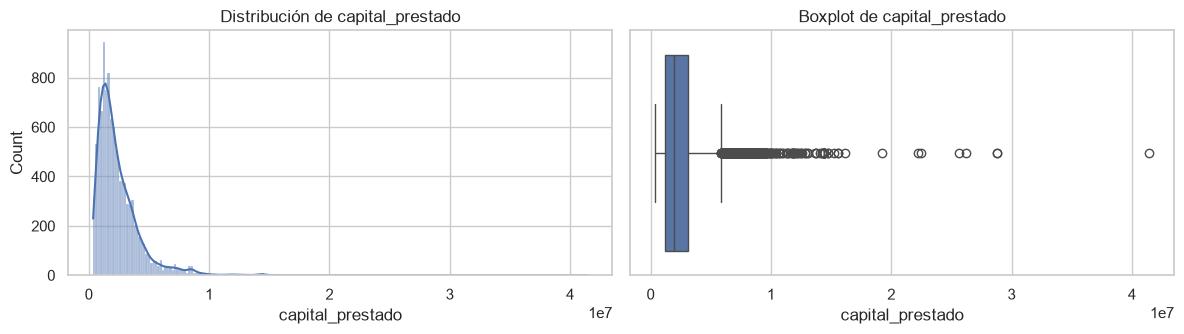

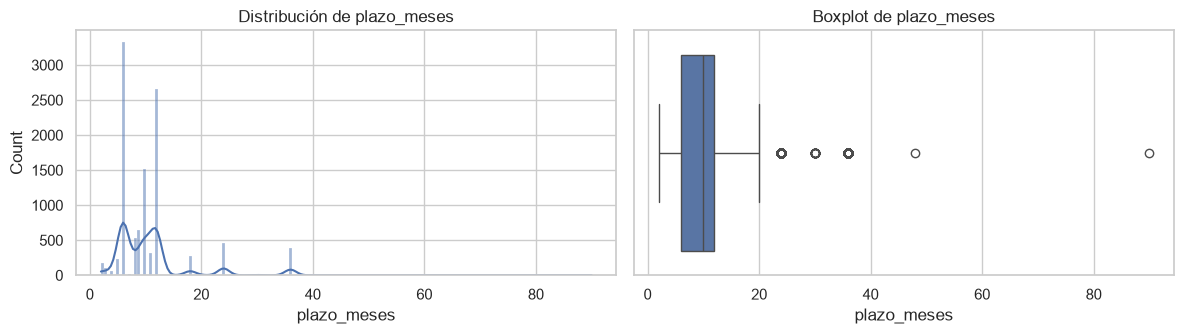

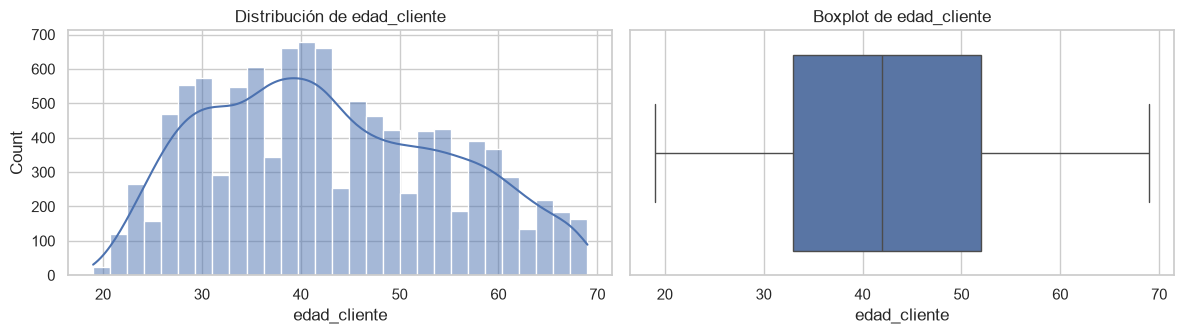

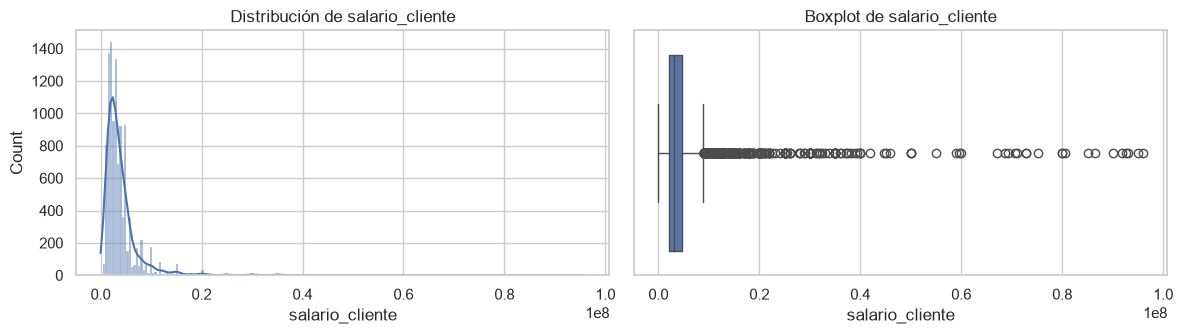

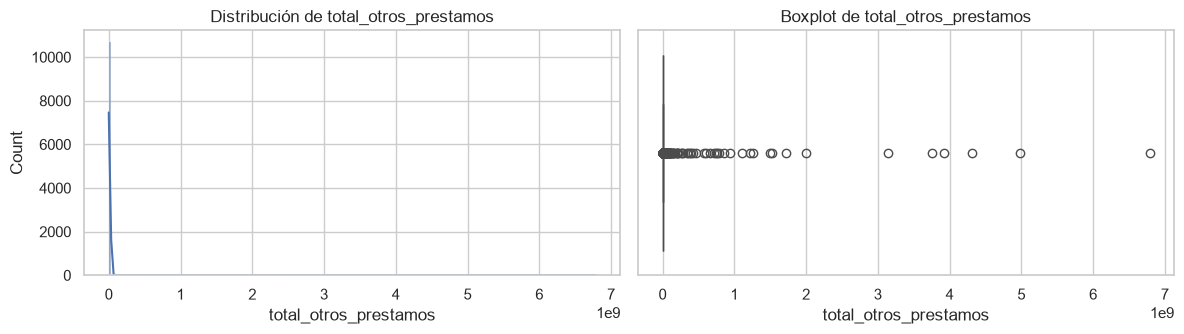

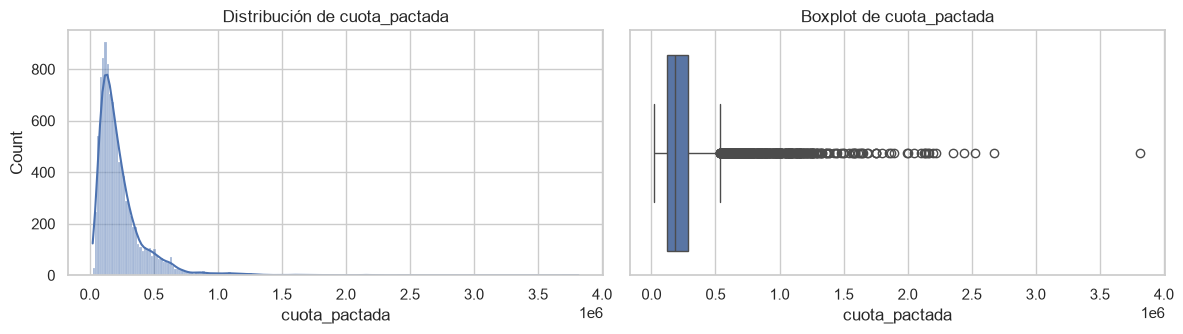

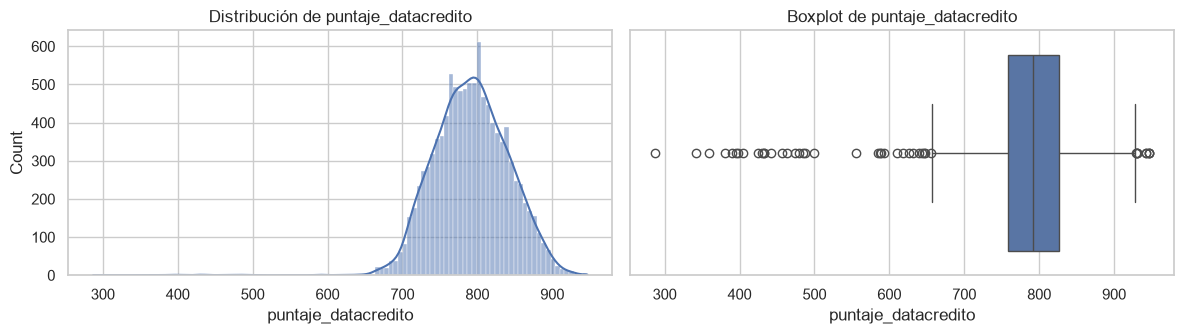

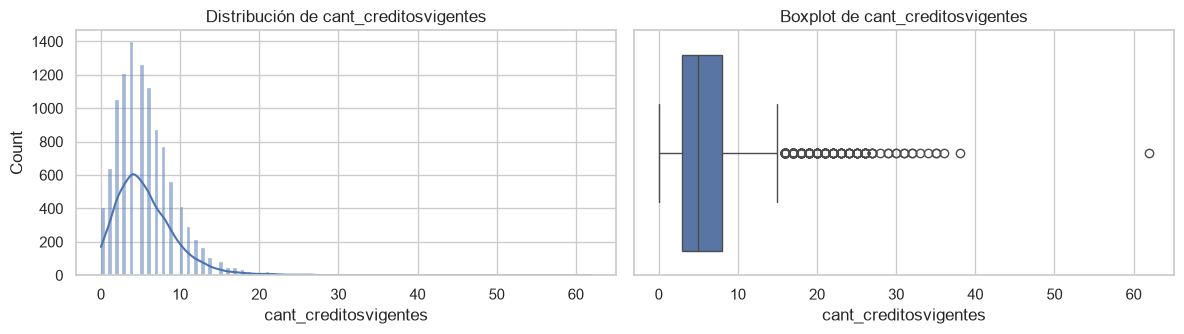

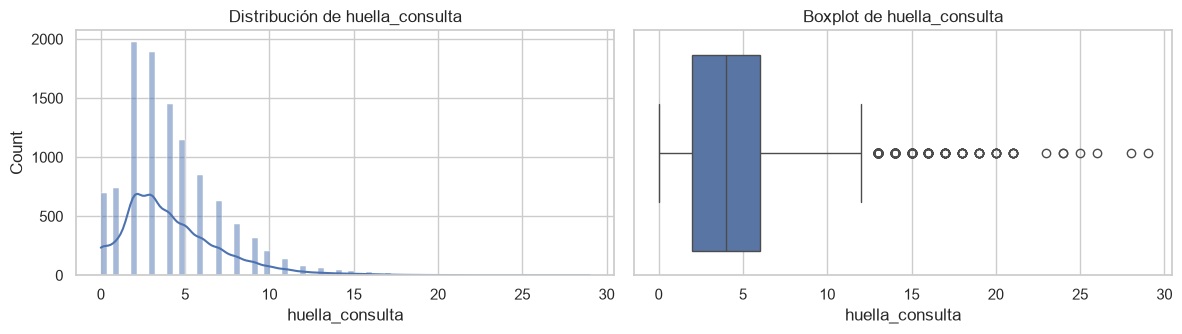

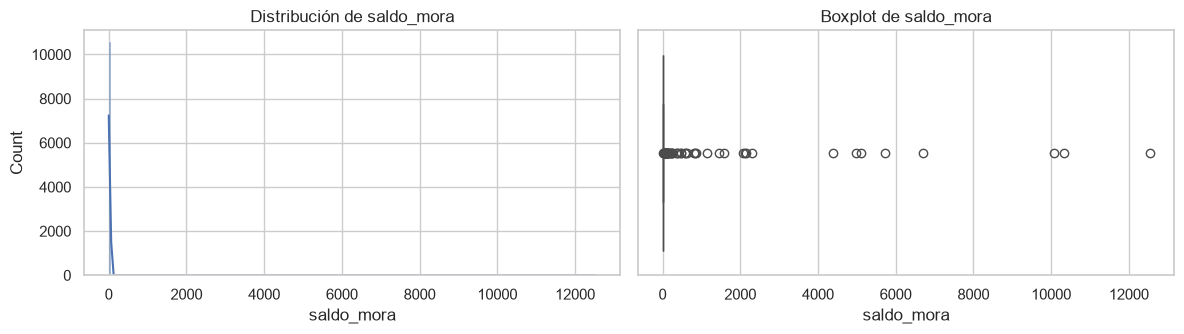

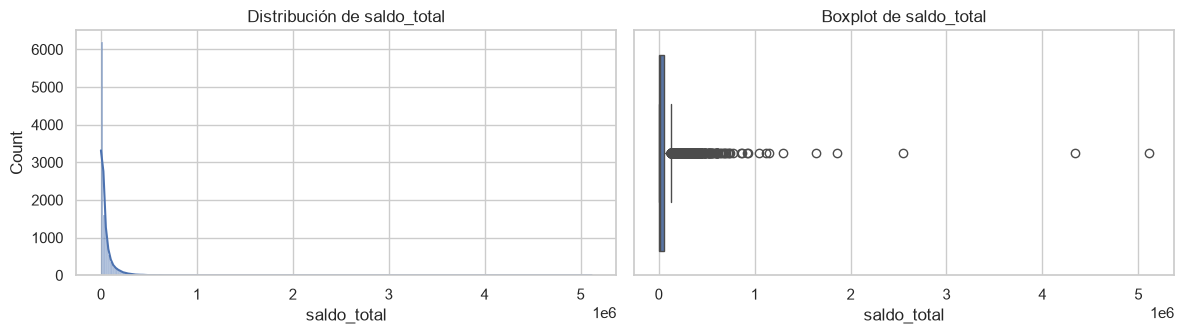

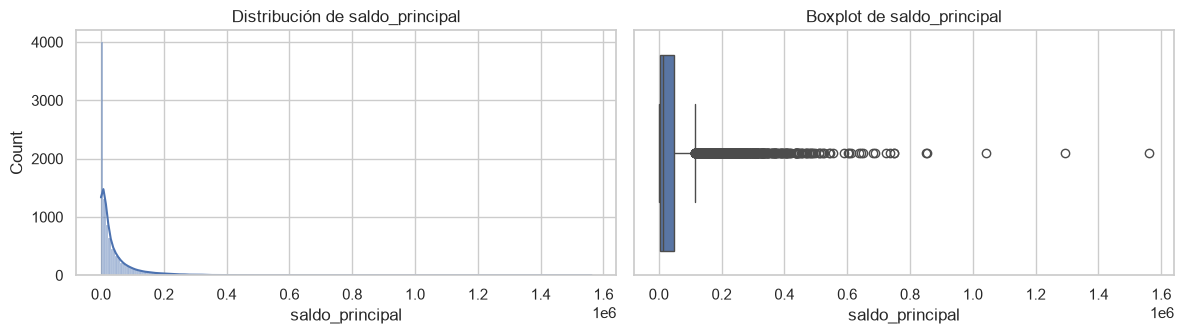

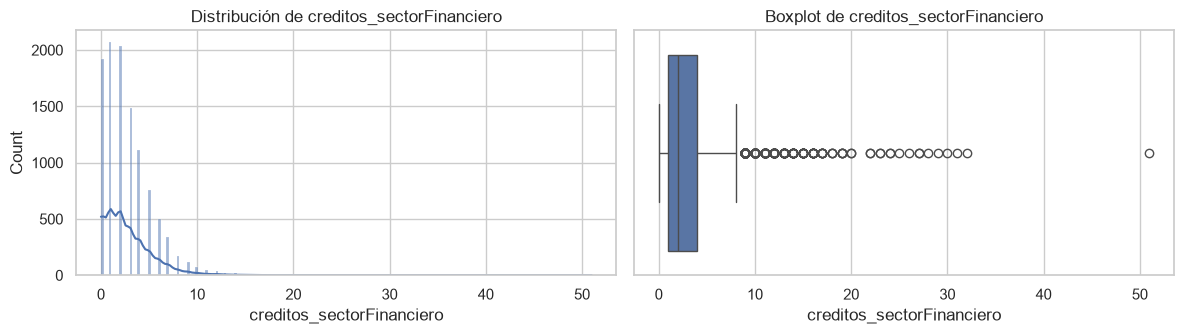

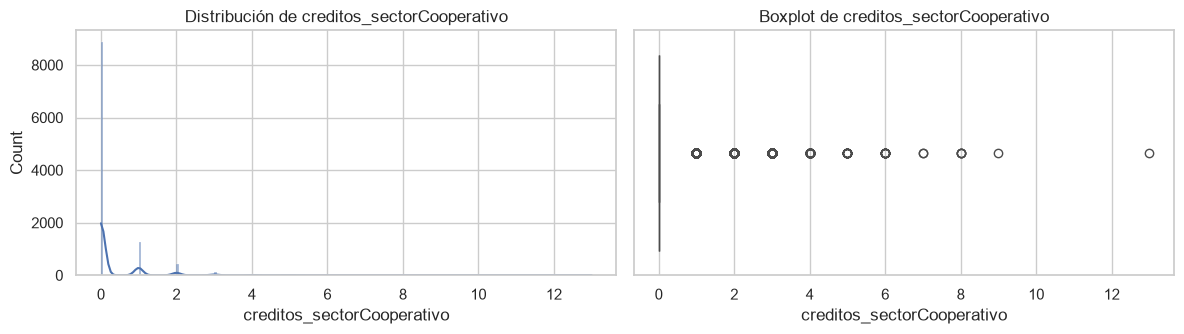

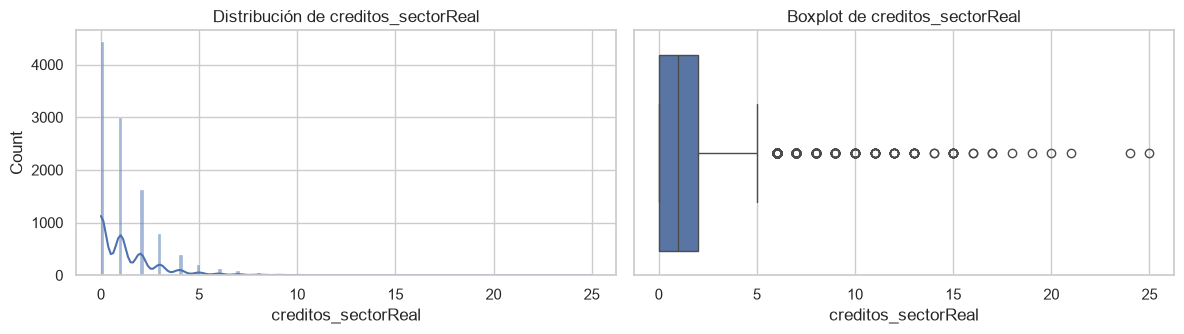

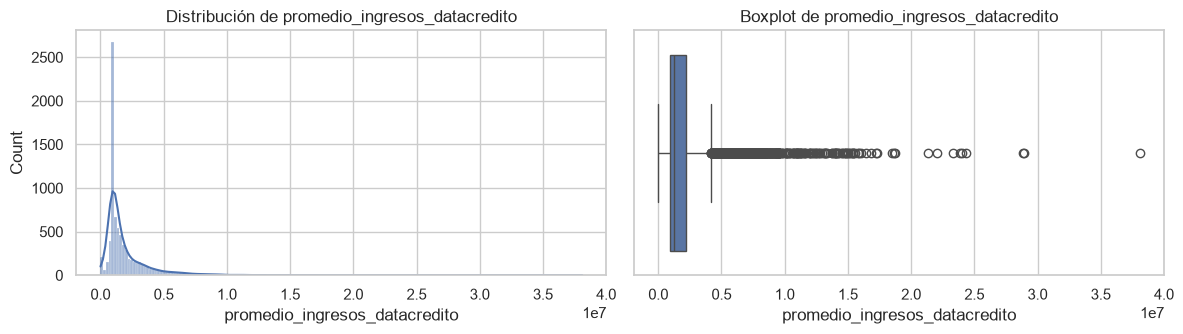

In [29]:
for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

    sns.histplot(df[col], kde=True, ax=axes[0])

    axes[0].set_title(f"Distribución de {col}")

    sns.boxplot(x=df[col], ax=axes[1])

    axes[1].set_title(f"Boxplot de {col}")

    plt.tight_layout()
    
    plt.show()

tipo_credito
4     7747
9     2876
10     116
6       21
7        2
68       1
Name: count, dtype: int64 



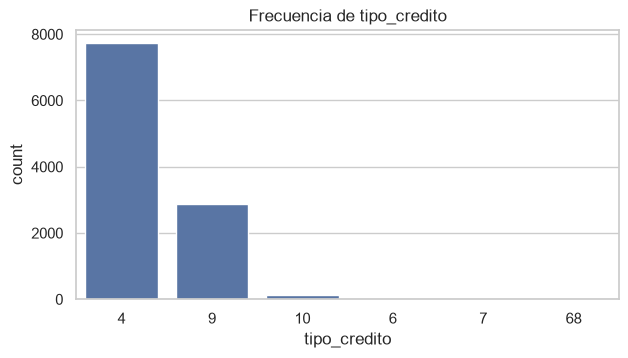

tipo_laboral
Empleado         6754
Independiente    4009
Name: count, dtype: int64 



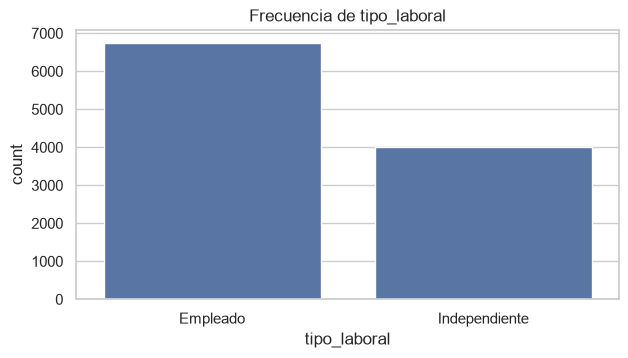

tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64 



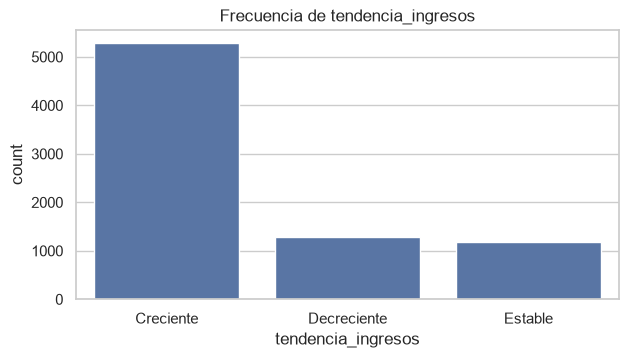

In [30]:
for col in cat_cols:

    print(df[col].value_counts(dropna=False), "\n")

    plt.figure(figsize=(7, 3.5))

    sns.countplot(data=df, x=col, order=df[col].value_counts().index)

    plt.title(f"Frecuencia de {col}")
    
    plt.show()

## Hallamos que

los tipos de crédito 7 y 68 tienen 2 registros y 1 registro respectivamente. Son categorías raras que conviene agrupar como “Otros”.

## 8. Análisis bivariable (contra el target)

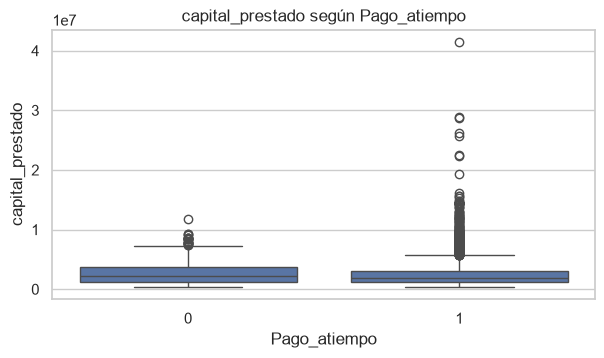

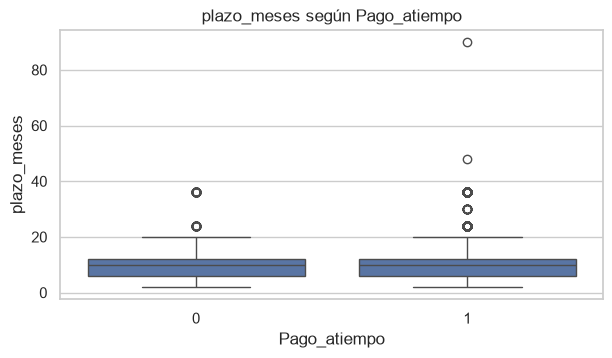

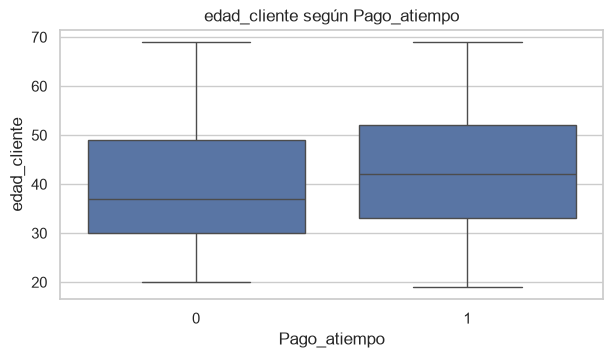

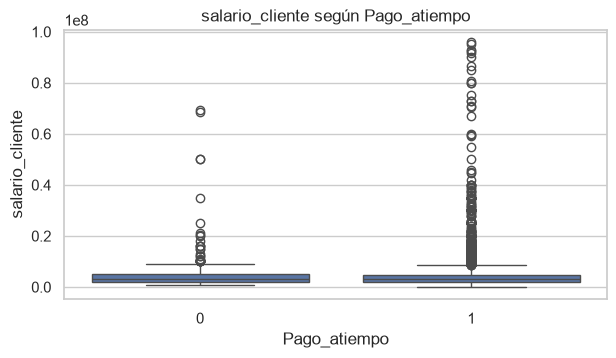

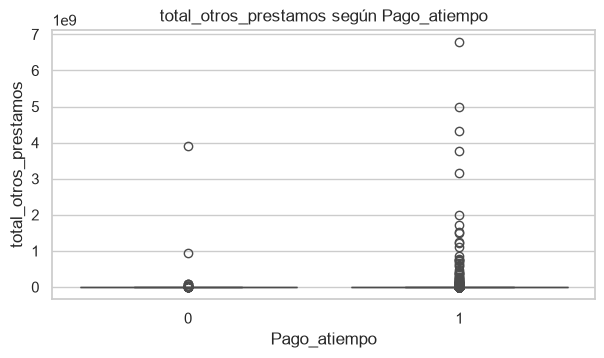

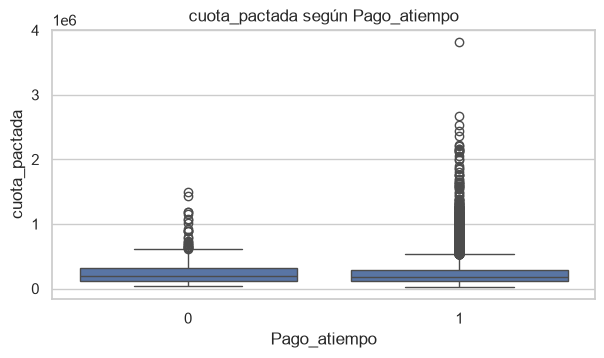

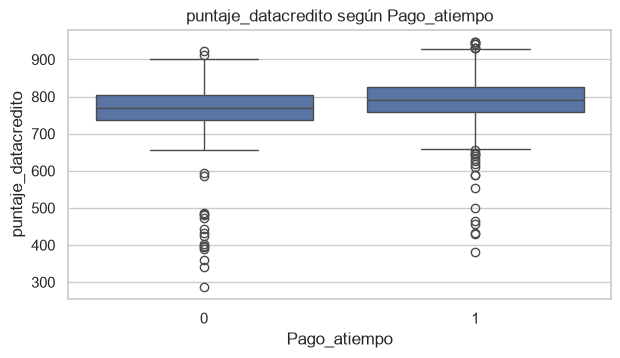

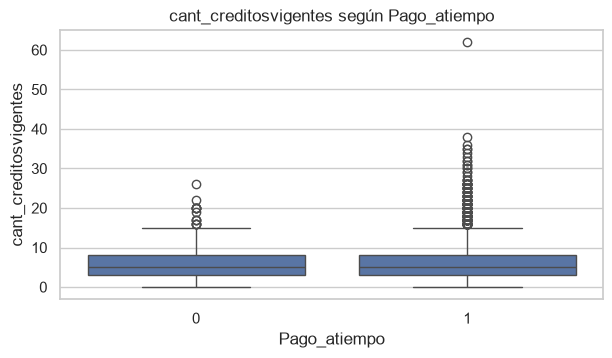

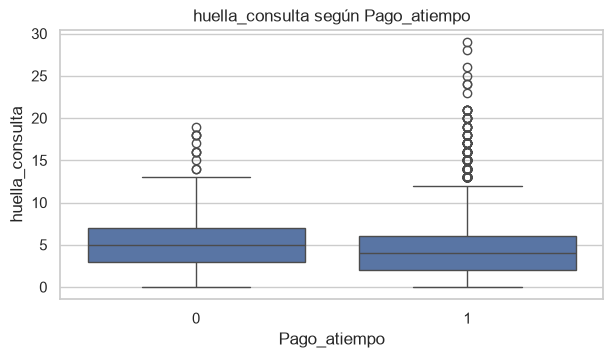

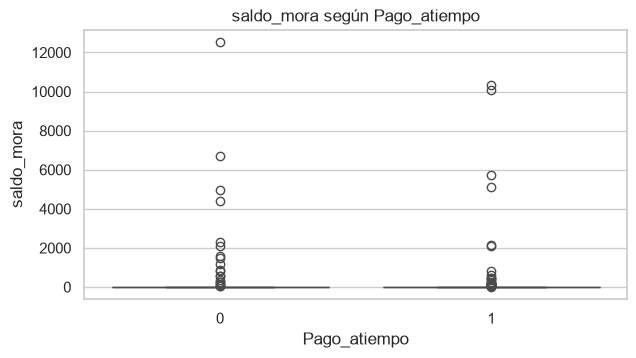

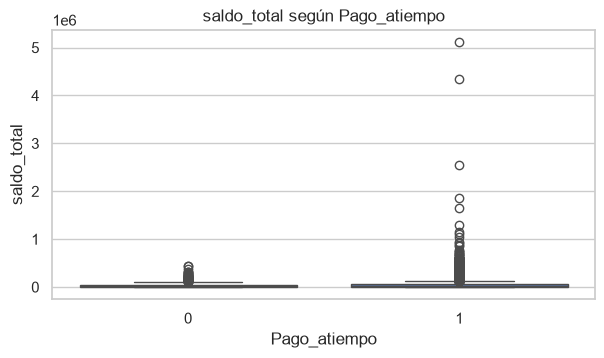

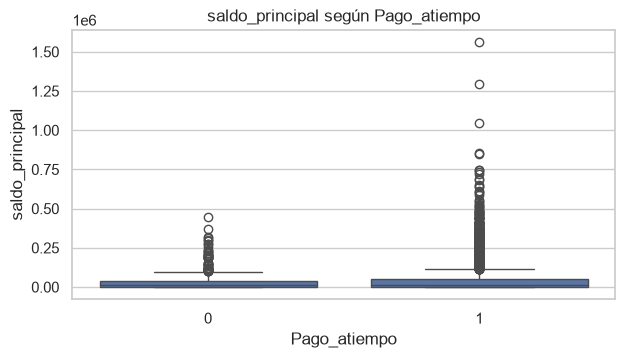

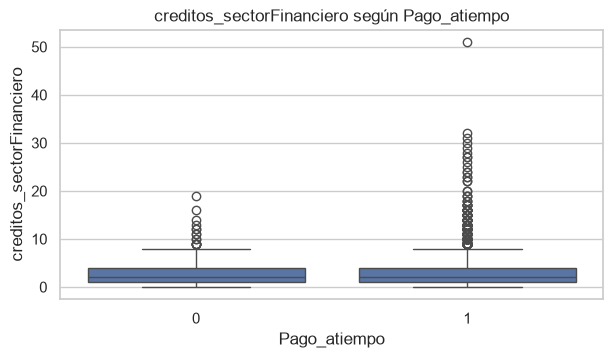

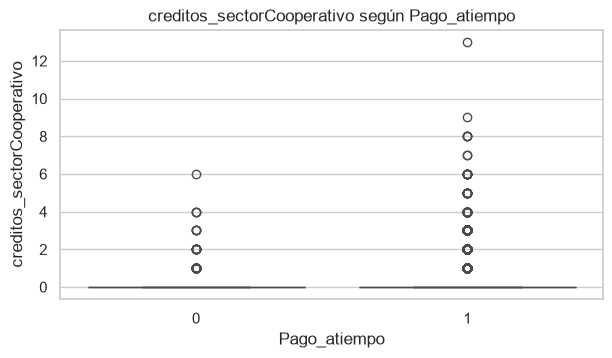

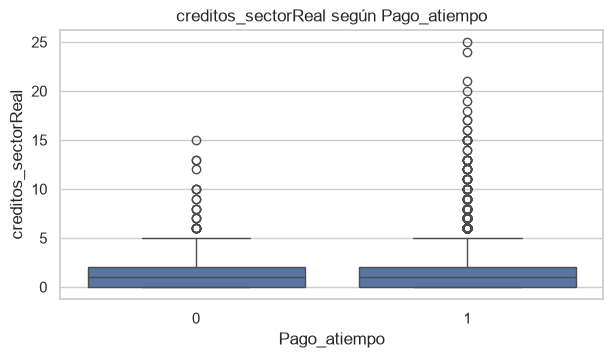

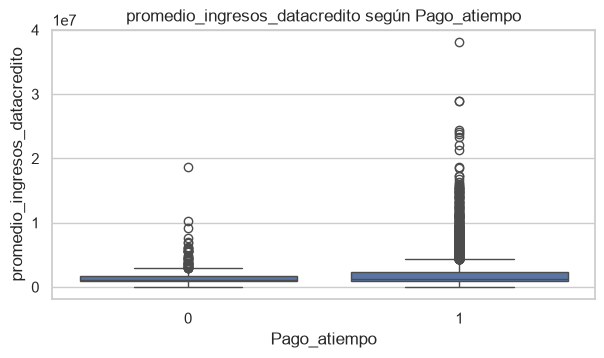

Pago_atiempo,0,1
capital_prestado,2268000.0,1908446.4
plazo_meses,10.0,10.0
edad_cliente,37.0,42.0
salario_cliente,3000000.0,3000000.0
total_otros_prestamos,900000.0,1000000.0
cuota_pactada,199002.0,182576.0
puntaje_datacredito,769.0,792.0
cant_creditosvigentes,5.0,5.0
huella_consulta,5.0,4.0
saldo_mora,0.0,0.0


In [31]:
for col in num_cols:

    plt.figure(figsize=(7, 3.5))

    sns.boxplot(data=df, x="Pago_atiempo", y=col)

    plt.title(f"{col} según Pago_atiempo")
    
    plt.show()

df.groupby("Pago_atiempo")[num_cols].median().T.round(1)

## Observamos quienes no pagan, comparados con quienes pagan:

- son más jóvenes (mediana de 37 vs 42 años);
- tienen peor puntaje de Datacrédito (769 vs 792);
- tienen más consultas recientes (5 vs 4);
- piden más capital (2,27M vs 1,91M).

In [32]:
for col in cat_cols:

    tabla = df.groupby(col, observed=True)["Pago_atiempo"].agg(["count", "mean"])

    tabla["tasa_impago_%"] = ((1 - tabla["mean"]) * 100).round(2)
    
    print(tabla, "\n")

pd.pivot_table(df, index="tipo_laboral", columns="tendencia_ingresos",
               values="Pago_atiempo", aggfunc="mean", observed=True).round(3)

              count      mean  tasa_impago_%
tipo_credito                                
10              116  0.974138           2.59
4              7747  0.953143           4.69
6                21  0.571429          42.86
68                1  1.000000           0.00
7                 2  1.000000           0.00
9              2876  0.952712           4.73 

               count      mean  tasa_impago_%
tipo_laboral                                 
Empleado        6754  0.957062           4.29
Independiente   4009  0.944874           5.51 

                    count      mean  tasa_impago_%
tendencia_ingresos                                
Decreciente          1291  0.937258           6.27
Estable              1188  0.953704           4.63
Creciente            5294  0.960899           3.91 



tendencia_ingresos,Decreciente,Estable,Creciente
tipo_laboral,,,
Empleado,0.941,0.955,0.964
Independiente,0.927,0.952,0.952


## Vemos lo siguientes:

- Ingresos decrecientes tienen 6,27% de impago, frente a 3,91% de los crecientes.
- Los independientes tienen 5,51% de impago, frente a 4,29% de los empleados.
- El tipo de crédito 6 tiene 42,9% de impago, pero son solo 21 casos. Una tasa calculada con tan pocos casos no es confiable, y hay que decirlo.

## 9. Análisis multivariable

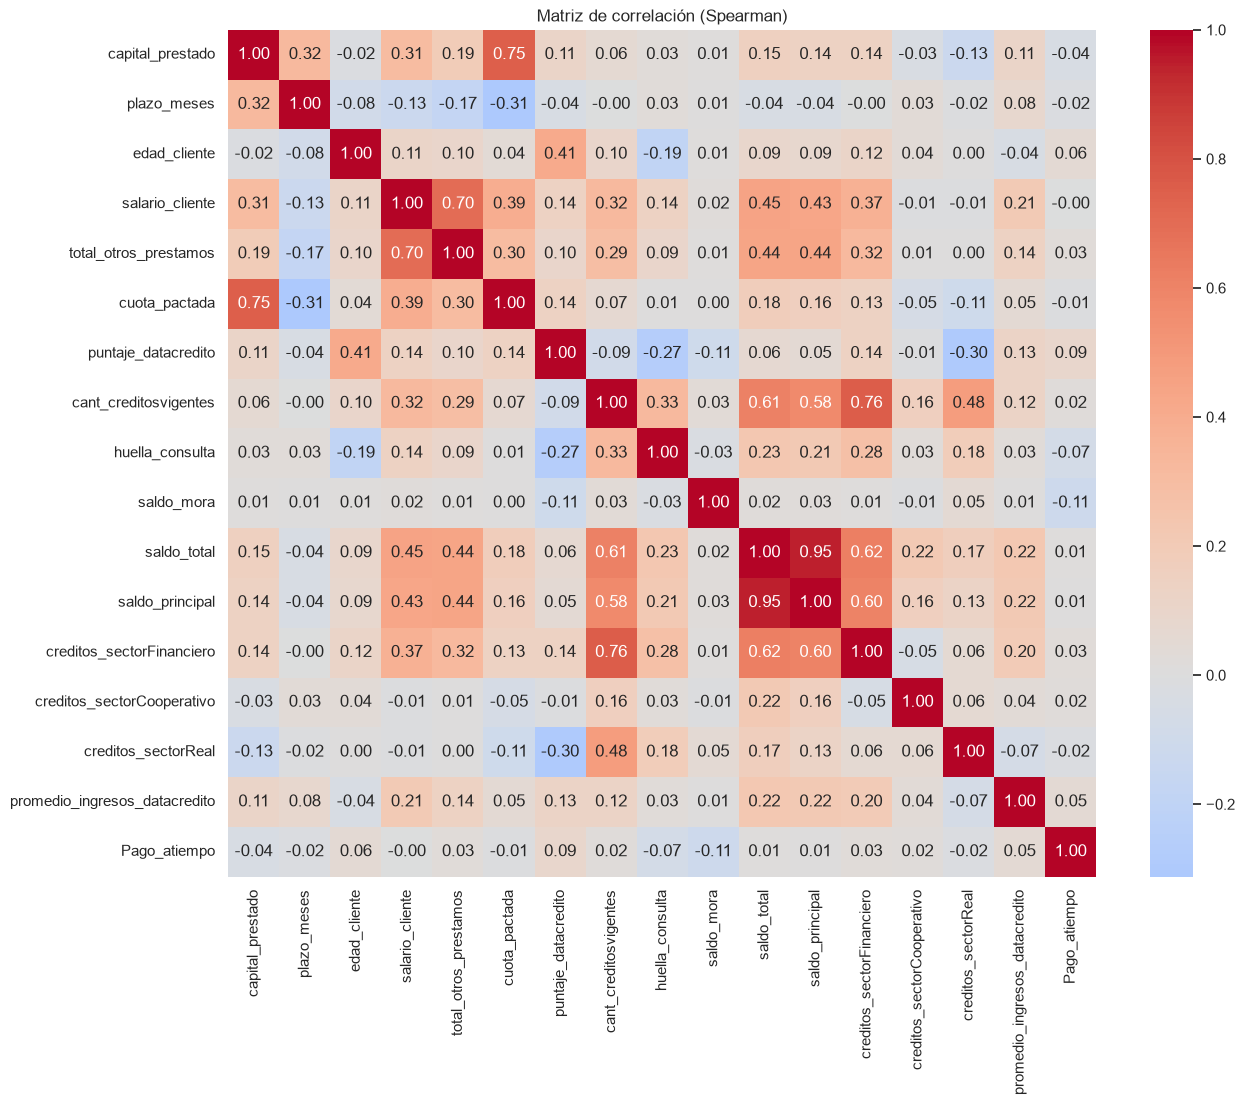

saldo_total            saldo_principal              0.946326
cant_creditosvigentes  creditos_sectorFinanciero    0.755234
capital_prestado       cuota_pactada                0.750691
salario_cliente        total_otros_prestamos        0.702466
dtype: float64

In [33]:
corr = df[num_cols + ["Pago_atiempo"]].corr(method="spearman")
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación (Spearman)")
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pares[pares.abs() > 0.7].sort_values(ascending=False)

## Aqui obersvamos:

saldo_total y saldo_principal tienen correlación de 0,95. Son casi la misma información (multicolinealidad) y conviene quedarse con una sola.
capital_prestado y cuota_pactada tienen 0,75: a más capital, más cuota.

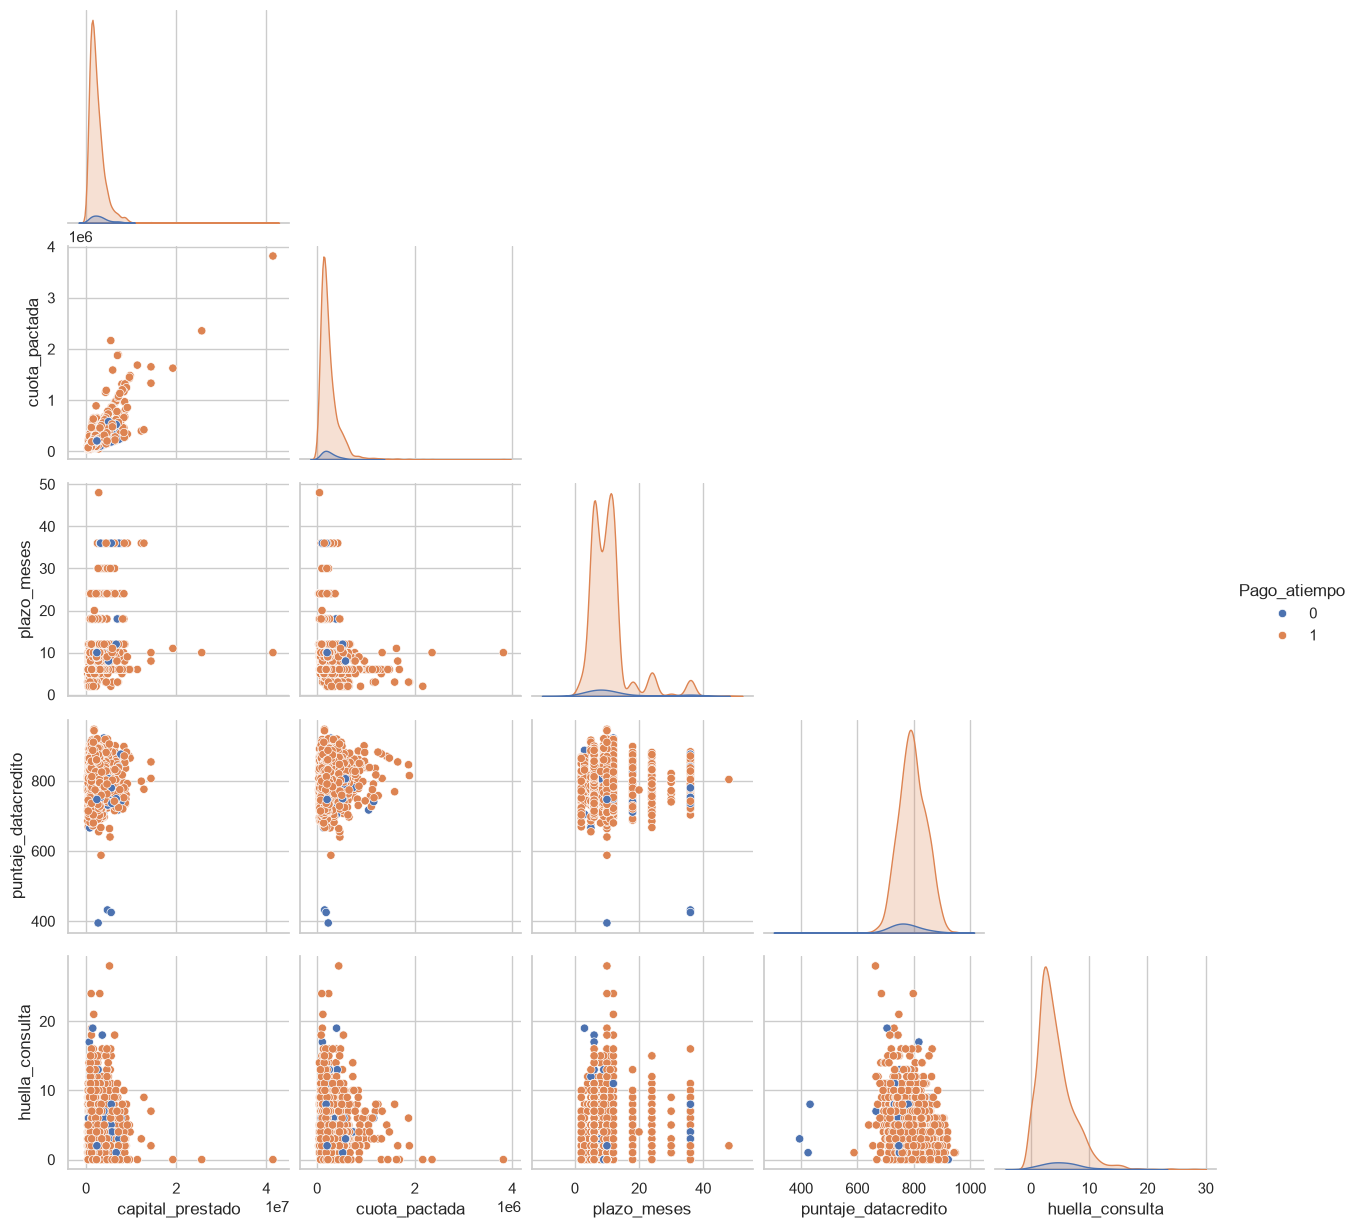

tendencia_ingresos,Decreciente,Estable,Creciente
tipo_laboral,,,
Empleado,0.173,0.119,0.708
Independiente,0.151,0.231,0.618


In [34]:
vars_pair = ["capital_prestado", "cuota_pactada", "plazo_meses",
             "puntaje_datacredito", "huella_consulta"]
sns.pairplot(df[vars_pair + ["Pago_atiempo"]].sample(2000, random_state=42),
             hue="Pago_atiempo", corner=True)
plt.show()

pd.crosstab(df["tipo_laboral"], df["tendencia_ingresos"], normalize="index").round(3)

## 10. Variables derivadas

In [35]:
df["mes_prestamo"] = df["fecha_prestamo"].dt.month

df["dia_semana"] = df["fecha_prestamo"].dt.dayofweek

df["sin_info_buro"] = df["promedio_ingresos_datacredito"].isna().astype(int)

df["carga_cuota_salario"] = df["cuota_pactada"] / df["salario_cliente"]

df["endeudamiento"] = df["total_otros_prestamos"] / df["salario_cliente"]

derivadas = ["mes_prestamo", "dia_semana", "sin_info_buro", "carga_cuota_salario", "endeudamiento"]

print(df.groupby("Pago_atiempo")[derivadas].median().T)

df.groupby("sin_info_buro")["Pago_atiempo"].mean()

Pago_atiempo                0         1
mes_prestamo         4.000000  4.000000
dia_semana           4.000000  3.000000
sin_info_buro        0.000000  0.000000
carga_cuota_salario  0.060904  0.061206
endeudamiento        0.333333  0.337640


/var/folders/nz/4v7s8xvj1z7g8nbsp63m156m0000gn/T/ipykernel_43762/1296942631.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dia_semana"] = df["fecha_prestamo"].dt.dayofweek


sin_info_buro
0    0.956211
1    0.942662
Name: Pago_atiempo, dtype: float64

# 11. 📝 Conclusiones

Reglas de validación:

Variable    -	Regla
edad_cliente    -	entre 18 y 100
salario_cliente -	mayor que 0 y menor o igual a 100.000.000
puntaje_datacredito -	entre 150 y 950
tendencia_ingresos  -	∈ {Decreciente, Estable, Creciente}
tipo_laboral    -	∈ {Empleado, Independiente}
capital_prestado, cuota_pactada, plazo_meses    -	mayores que 0 y no nulos
Pago_atiempo    -	∈ {0, 1}

Transformaciones propuestas:

logaritmo (log1p) a montos y saldos sesgados;
imputación por mediana para numéricas y por moda para categóricas, dentro del pipeline;
OneHotEncoder para tipo_credito y tipo_laboral;
OrdinalEncoder para tendencia_ingresos;
agrupar los tipos de crédito raros como “Otros”;
eliminar una de las dos variables saldo_total / saldo_principal;
manejar el desbalance de clases con class_weight.

Variables eliminadas: puntaje (data leakage) y saldo_mora_codeudor (casi constante).